# **INSTALL ALL DEPENDENCIES**

In [ ]:
!pip install torch torchvision torchaudio ultralytics scikit-learn opencv-python ultralytics opencv-contrib-python numpy pandas Pillow ipython matplotlib

# **IMPORT ALL AND VARIABLE AND GPU CHECK**

In [2]:
import os
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import zipfile

from pathlib import Path
from sklearn.model_selection import train_test_split
from ultralytics import YOLO
from PIL import Image
from IPython.display import display, FileLink
from sklearn.metrics import (
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve, auc,
    precision_recall_curve
)
from sklearn.preprocessing import LabelBinarizer


SEED = 49
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


TEST_DIR = Path("/kaggle/working/chest_xray_split/test")
INPUT_DIR = Path("/kaggle/input")
DATASET_DIR = Path("/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray")
YOLO_DATA = Path("/kaggle/working/chest_xray_split")
CLASSES = ["NORMAL", "PNEUMONIA"]
CLASS_DIR = ["train", "val", "test"]
IMG_ALLOW = [".jpg", ".jpeg", ".png"]

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Enable GPU in Kaggle Settings!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


# **MAIN DATASET INFORMATION**

In [3]:
for split in CLASS_DIR:
    print(f"\n{split.upper()}")

    for cls in CLASSES:
        folder = DATASET_DIR / split / cls

        if folder.exists():
            images = [
                f for f in folder.iterdir()
                if f.suffix.lower() in IMG_ALLOW
            ]

            print(f"{cls}: {len(images)} images")


TRAIN
NORMAL: 1341 images
PNEUMONIA: 3875 images

VAL
NORMAL: 8 images
PNEUMONIA: 8 images

TEST
NORMAL: 234 images
PNEUMONIA: 390 images


# **MODIFYING DATASETS**

In [4]:
# Read original training images
images = []
labels = []

for cls in CLASSES:
    folder = DATASET_DIR / "train" / cls
    folderV = DATASET_DIR / "val" / cls

    for img in folder.iterdir():
        if img.suffix.lower() in IMG_ALLOW:
            images.append(str(img))
            labels.append(cls)
            
    for img in folderV.iterdir():
        if img.suffix.lower() in IMG_ALLOW:
            images.append(str(img))
            labels.append(cls)

# Stratified training split, want use validation data
train_paths, val_paths, train_labels, val_labels = (
    train_test_split(
        images,
        labels,
        test_size = 0.10,
        random_state = SEED,
        stratify = labels
    )
)

# Keep paths instead of copying images
train_df = pd.DataFrame({
    "image": train_paths,
    "label": train_labels
})

val_df = pd.DataFrame({
    "image": val_paths,
    "label": val_labels
})

# Original test set
test_paths = []
test_labels = []

for cls in CLASSES:
    folder = DATASET_DIR / "test" / cls

    for img in folder.iterdir():
        if img.suffix.lower() in IMG_ALLOW:
            test_paths.append(str(img))
            test_labels.append(cls)

test_df = pd.DataFrame({
    "image": test_paths,
    "label": test_labels
})

if YOLO_DATA.exists():
    shutil.rmtree(YOLO_DATA)

# Create YOLO compatible folders
for split in CLASS_DIR:
    for cls in CLASSES:
        (YOLO_DATA / split / cls).mkdir(parents=True, exist_ok=True)

# Create symbolic links instead of copying images
def create_symlinks(df, split):
    for _, row in df.iterrows():

        source = Path(row["image"])
        label = row["label"]

        destination = ( YOLO_DATA / split / label / source.name )
        destination.symlink_to(source)

# Populate all three splits
create_symlinks(train_df, "train")
create_symlinks(val_df, "val")
create_symlinks(test_df, "test")

print("YOLO dataset prepared!")
print("Dataset location:", YOLO_DATA)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

YOLO dataset prepared!
Dataset location: /kaggle/working/chest_xray_split
Training: 4708
Validation: 524
Testing: 624


In [5]:
for split in CLASS_DIR:
    print(f"\n{split.upper()}")
    for cls in CLASSES:
        folder = YOLO_DATA / split / cls
        print( cls, ":", len(list(folder.iterdir())) )


TRAIN
NORMAL : 1214
PNEUMONIA : 3494

VAL
NORMAL : 135
PNEUMONIA : 389

TEST
NORMAL : 234
PNEUMONIA : 390


# **MODEL LOADED**

In [6]:
MODEL_NAME = "yolo26x-cls"
model = YOLO(MODEL_NAME)
print("Model loaded")

Model loaded


In [32]:
results = model.train(
    data=str(YOLO_DATA),
    epochs=50,
    imgsz=224,
    batch=64,
    device=[0, 1],
    workers=4,
    patience=10,
    optimizer="AdamW",
    lr0=0.0001,
    pretrained=True,
    #cache=True,
    amp=True,
    project="/kaggle/working/runs/classify",
    name="yolo26x_chest_xray_v3",
    exist_ok=True,
    save=True,
    plots=True,
    seed=SEED
)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/chest_xray_split, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/classify/

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem       loss  Instances       Size
       2/50      3.24G     0.1083         18        224: 100% ━━━━━━━━━━━━ 74/74 1.6it/s 45.3s0.3ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 5/5 10.3it/s 0.5s.2s
                   all      0.901          1

      Epoch    GPU_mem       loss  Instances       Size
       3/50      3.24G     0.1283         18        224: 100% ━━━━━━━━━━━━ 74/74 1.6it/s 45.2s0.2ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 5/5 10.7it/s 0.5s.2s
                   all      0.964          1

      Epoch    GPU_mem       loss  Instances       Size
       4/50      3.24G    0.09907         18        224: 100% ━━━━━━━━━━━━ 74/74 1.7it/s 43.9s0.3ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 5/5 10.4it/s 0.5s.2s
                   all       0.96          1

      Epoch    GPU_mem       loss  Instances       Size
       5/50      3.24G     0.1127         18        224: 100% ━━━━━━━━━━━━ 74/74 1

# **OUTPUT SHOWCASE**

**CHECKING MODEL IS FOUND**

In [34]:
# Your completed training folder
RUN_DIR = Path("/kaggle/working/runs/classify/yolo26x_chest_xray_v3")

# Check that training completed and best.pt exists
BEST_MODEL = RUN_DIR / "weights" / "best.pt"
LAST_MODEL = RUN_DIR / "weights" / "last.pt"
CSV_FILE = RUN_DIR / "results.csv"

print("Best model exists:", BEST_MODEL.exists())
print("Last model exists:", LAST_MODEL.exists())
print("Training results exist:", CSV_FILE.exists())

assert BEST_MODEL.exists(), "best.pt was not found. Check RUN_DIR."

Best model exists: True
Last model exists: True
Training results exist: True


In [36]:
# Paths
OUTPUT_DIR = Path("/kaggle/working/final_chest_xray_results_v3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    
# Clear PyTorch cached memory
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

model = YOLO(str(BEST_MODEL))

# Class names from trained model
names = model.names

# Collect test images and true labels
image_paths = []
true_labels = []

for cls in CLASSES:
    for p in (TEST_DIR / cls).glob("*"):
        if p.suffix.lower() in IMG_ALLOW:
            image_paths.append(str(p))
            true_labels.append(cls)

# Predict all test images
predictions = model.predict(
    source=image_paths,
    imgsz=224,
    batch=64,
    device=[0, 1],
    verbose=False
)

predicted_labels = [
    names[int(result.probs.top1)] for result in predictions
]
confidence = [
    float(result.probs.top1conf) for result in predictions
]

# Results table
results_df = pd.DataFrame({
    "image": image_paths,
    "actual": true_labels,
    "predicted": predicted_labels,
    "confidence": confidence
})

results_df["correct"] = ( results_df["actual"] == results_df["predicted"] )
results_df.to_csv( OUTPUT_DIR / "test_predictions.csv", index=False )

print(results_df.head(10))
print("\nTest accuracy:", results_df["correct"].mean())

WARNING ⚠️ NMS time limit 2.050s exceeded
                                               image  actual  predicted  \
0  /kaggle/working/chest_xray_split/test/NORMAL/I...  NORMAL     NORMAL   
1  /kaggle/working/chest_xray_split/test/NORMAL/I...  NORMAL     NORMAL   
2  /kaggle/working/chest_xray_split/test/NORMAL/N...  NORMAL     NORMAL   
3  /kaggle/working/chest_xray_split/test/NORMAL/N...  NORMAL     NORMAL   
4  /kaggle/working/chest_xray_split/test/NORMAL/I...  NORMAL     NORMAL   
5  /kaggle/working/chest_xray_split/test/NORMAL/N...  NORMAL  PNEUMONIA   
6  /kaggle/working/chest_xray_split/test/NORMAL/N...  NORMAL     NORMAL   
7  /kaggle/working/chest_xray_split/test/NORMAL/N...  NORMAL     NORMAL   
8  /kaggle/working/chest_xray_split/test/NORMAL/N...  NORMAL     NORMAL   
9  /kaggle/working/chest_xray_split/test/NORMAL/N...  NORMAL     NORMAL   

   confidence  correct  
0    0.975731     True  
1    0.992055     True  
2    0.983671     True  
3    0.746372     True  
4    0.

YOLO26x CHEST X-RAY FINAL EVALUATION

Evaluating model on test set...
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26x-cls summary (fused): 94 layers, 28,334,978 parameters, 0 gradients, 110.7 GFLOPs
train: /kaggle/working/chest_xray_split/train... found 4708 images in 2/2 classes ✅ 
val: /kaggle/working/chest_xray_split/val... found 524 images in 2/2 classes ✅ 
test: /kaggle/working/chest_xray_split/test... found 624 images in 2/2 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 669.7±151.6 MB/s, size: 322.5 KB)
test: Scanning /kaggle/working/chest_xray_split/test... 624 images, 0 corrupt: 100% ━━━━━━━━━━━━ 624/624 201.3Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 20/20 2.4it/s 8.2s0.3s
                   all      0.934          1
Speed: 0.1ms preprocess, 5.2ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /kaggle/working/final_evaluation/test_results

Copying model and training

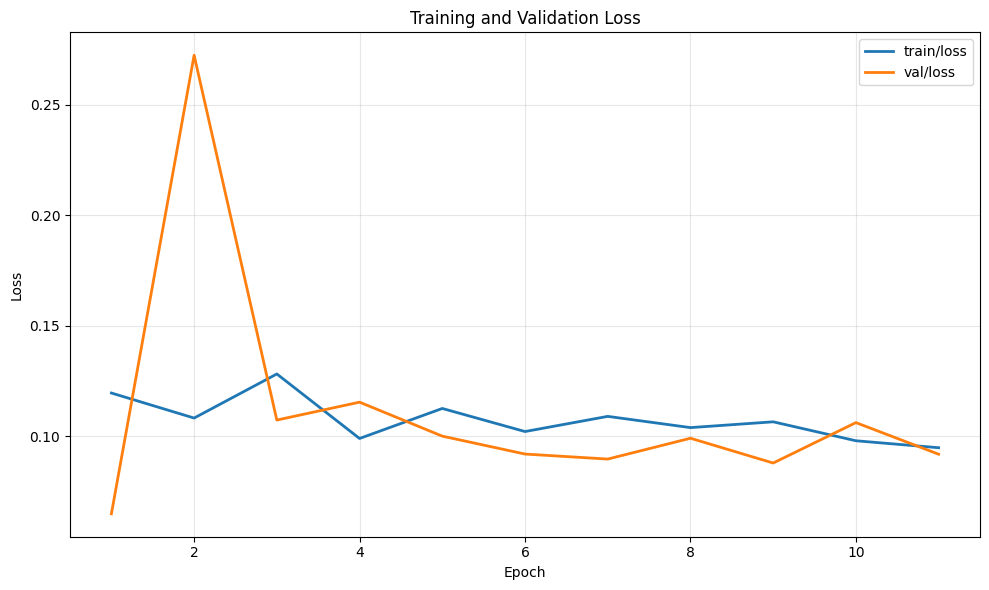

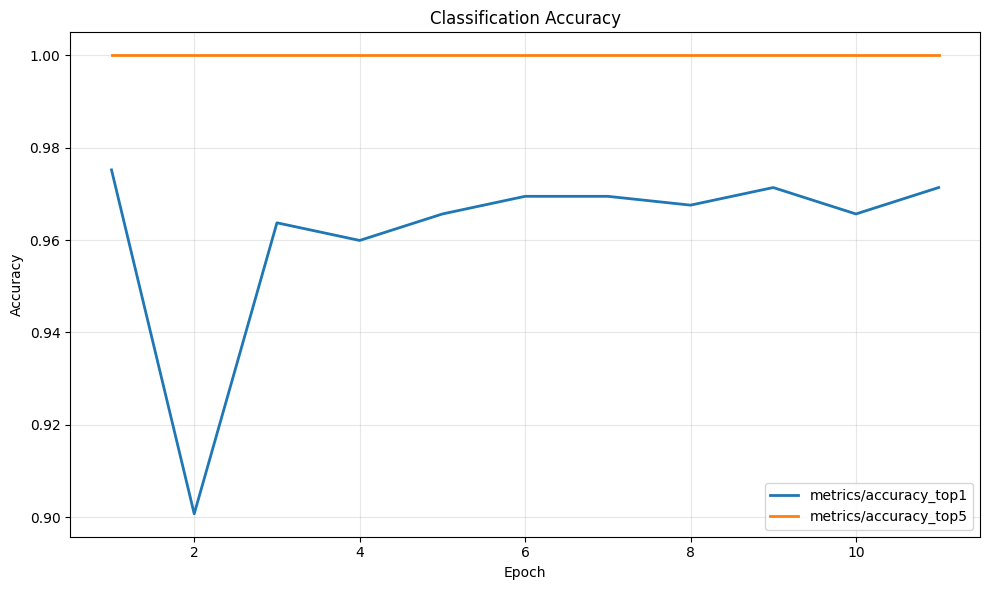


Creating prediction gallery...


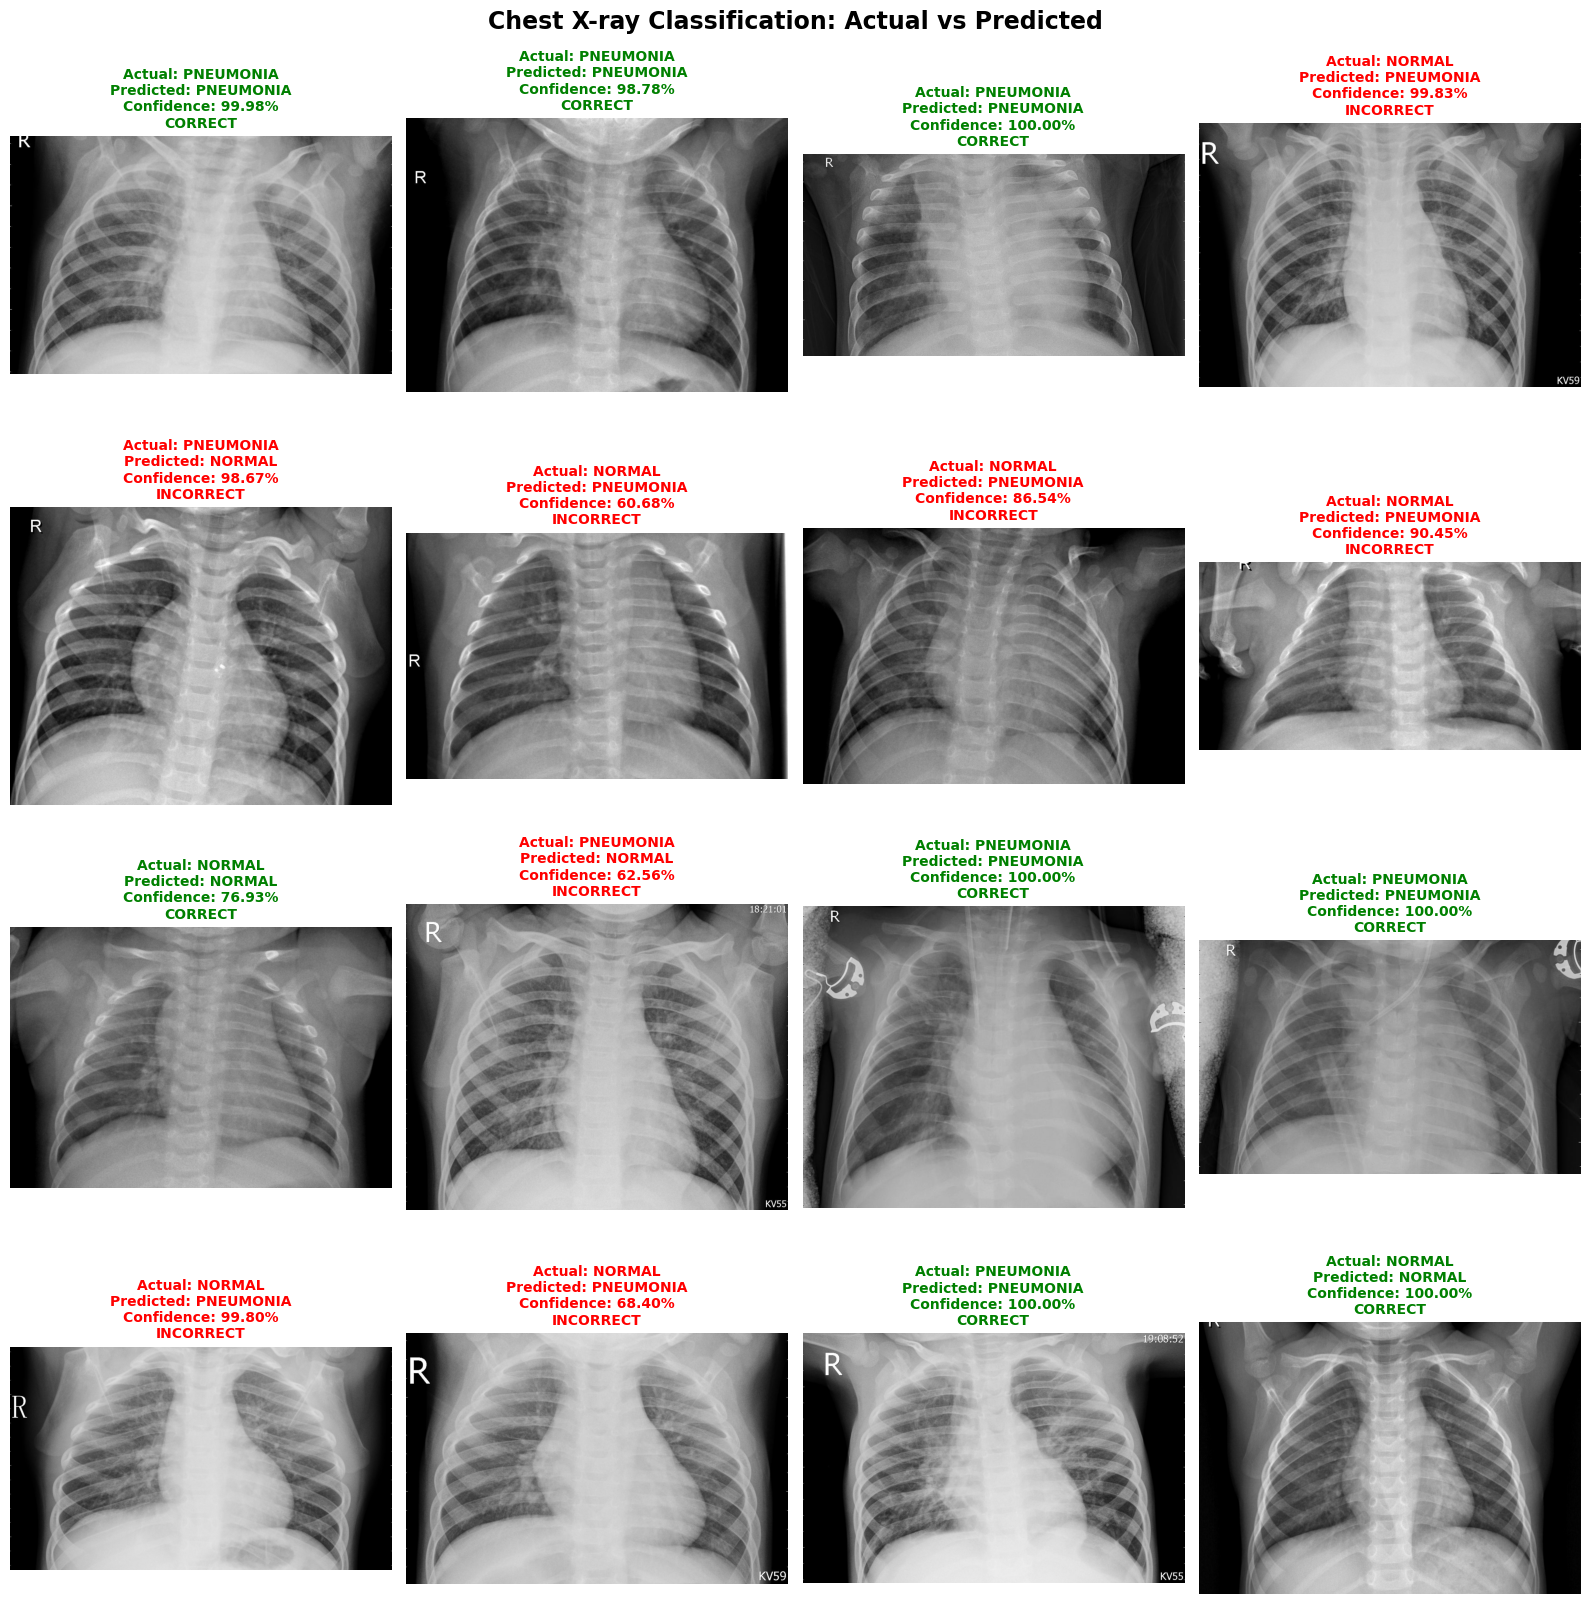


Creating confusion matrix...


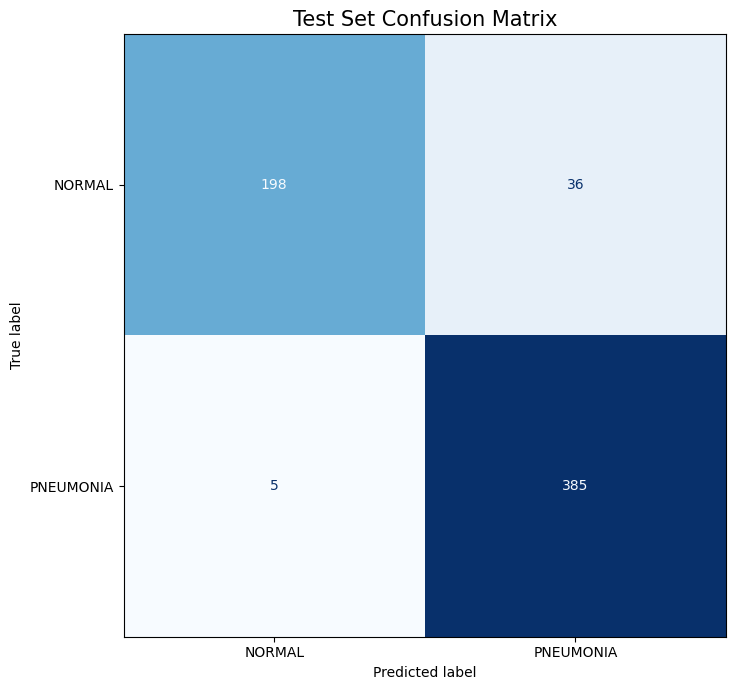


Confusion matrix:
[[198  36]
 [  5 385]]

Class labels: ['NORMAL', 'PNEUMONIA']

Classification report:


,precision,recall,f1-score,support
NORMAL,0.975369,0.846154,0.906178,234.000000
PNEUMONIA,0.914489,0.987179,0.949445,390.000000
accuracy,0.934295,0.934295,0.934295,0.934295
macro avg,0.944929,0.916667,0.927812,624.000000
weighted avg,0.937319,0.934295,0.933220,624.000000


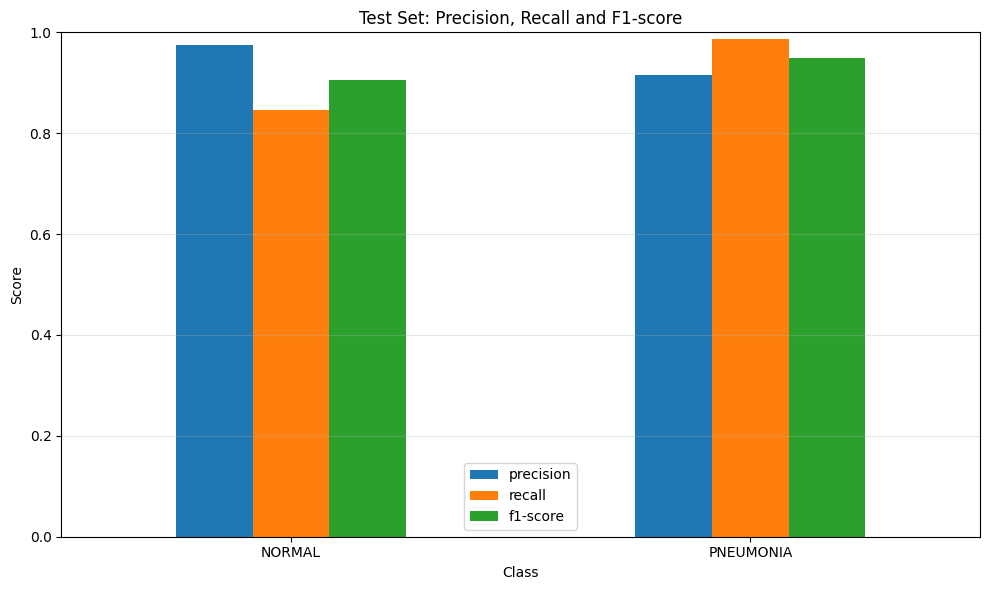

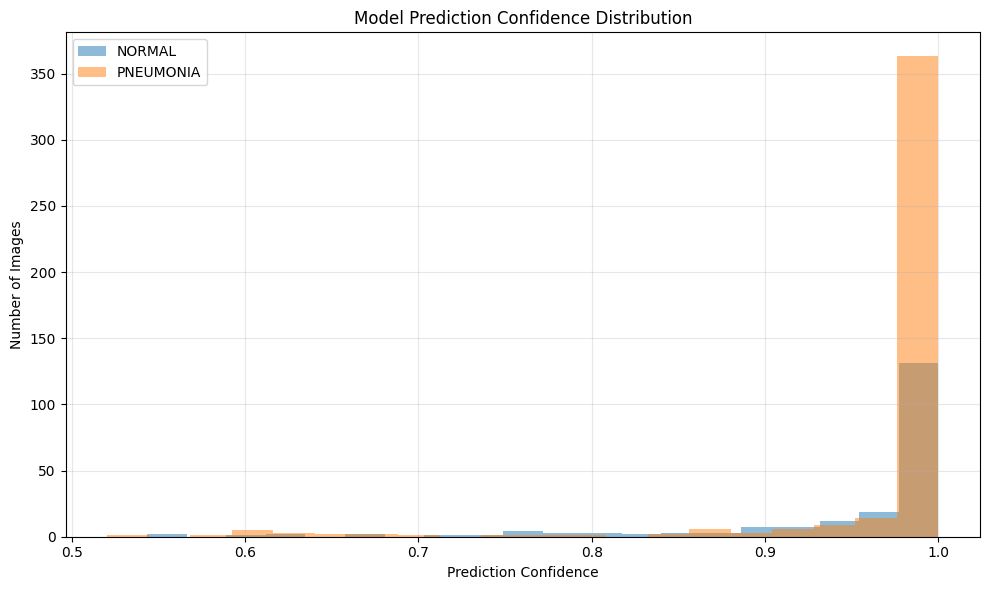


RULE-OUT RELATED METRICS


,Metric,Value
0,Pneumonia Sensitivity,0.987179
1,Normal Specificity,0.846154
2,False Negatives,5.000000
3,True Positives,385.000000
4,False Positives,36.000000
5,True Negatives,198.000000



TEST SUMMARY
Total test images: 624
Correct predictions: 583
Incorrect predictions: 41
Test accuracy: 0.9342948717948718

Creating downloadable ZIP...

ALL EVALUATION AND EXPORT TASKS COMPLETED!

Output folder: /kaggle/working/final_chest_xray_results
ZIP file: /kaggle/working/chest_xray_research_results.zip
ZIP size: 109.81 MB

Files included:
 - accuracy_curve.png
 - actual_vs_predicted_gallery.png
 - args.yaml
 - best.pt
 - classification_report.csv
 - confidence_distribution.png
 - confusion_matrix.png
 - confusion_matrix_normalized.png
 - last.pt
 - loss_curve.png
 - precision_recall_f1.png
 - results.csv
 - results.png
 - safety_metrics.csv
 - test_confusion_matrix.png
 - test_confusion_matrix_normalized.png
 - test_predictions.csv
 - test_summary.csv

DOWNLOAD YOUR COMPLETE RESEARCH RESULTS:


/kaggle/working/chest_xray_research_results.zip

In [ ]:
OUTPUT_DIR = Path("/kaggle/working/final_chest_xray_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TEST_DIR = Path("/kaggle/working/chest_xray_split")
assert TEST_DIR.exists(), "Corrected dataset folder was not found."

print("\nEvaluating model on test set...")

model.val(
    data=str(TEST_DIR),
    split="test",
    imgsz=224,
    batch=32,
    device=[0, 1],
    plots=True,
    project="/kaggle/working/final_evaluation",
    name="test_results",
    exist_ok=True
)

print("\nCopying model and training files...")

shutil.copy2(BEST_MODEL, OUTPUT_DIR / "best.pt")

if CSV_FILE.exists():
    shutil.copy2(CSV_FILE, OUTPUT_DIR / "results.csv")

if (RUN_DIR / "args.yaml").exists():
    shutil.copy2(RUN_DIR / "args.yaml", OUTPUT_DIR / "args.yaml")

for file in RUN_DIR.glob("*.png"):
    shutil.copy2(file, OUTPUT_DIR / file.name)

EVAL_DIR = Path("/kaggle/working/final_evaluation/test_results")

if EVAL_DIR.exists():
    for file in EVAL_DIR.glob("*.png"):
        shutil.copy2(file, OUTPUT_DIR / f"test_{file.name}")

# GRAPHS

if CSV_FILE.exists():

    df = pd.read_csv(CSV_FILE)
    df.columns = df.columns.str.strip()

    if "epoch" in df.columns:

        loss_cols = [
            c for c in df.columns
            if "loss" in c.lower() and df[c].notna().any()
        ]

        if loss_cols:
            plt.figure(figsize=(10, 6))

            for col in loss_cols:
                plt.plot(df["epoch"], df[col], label=col, linewidth=2)

            plt.title("Training and Validation Loss")
            plt.xlabel("Epoch")
            plt.ylabel("Loss")
            plt.grid(alpha=0.3)
            plt.legend()
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=300)
            plt.show()


        accuracy_cols = [
            c for c in df.columns
            if "accuracy" in c.lower() and df[c].notna().any()
        ]

        if accuracy_cols:
            plt.figure(figsize=(10, 6))

            for col in accuracy_cols:
                plt.plot(df["epoch"], df[col], label=col, linewidth=2)

            plt.title("Classification Accuracy")
            plt.xlabel("Epoch")
            plt.ylabel("Accuracy")
            plt.grid(alpha=0.3)
            plt.legend()
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / "accuracy_curve.png", dpi=300)
            plt.show()

# PREDICTION DATA

results_df = results_df.copy()
results_df["confidence"] = pd.to_numeric(results_df["confidence"], errors="coerce")
results_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)


print("\nCreating prediction gallery...")

correct_predictions = results_df[results_df["correct"]]
incorrect_predictions = results_df[~results_df["correct"]]

sample_correct = correct_predictions.sample(min(8, len(correct_predictions)), random_state=SEED)
sample_incorrect = incorrect_predictions.sample(min(8, len(incorrect_predictions)), random_state=SEED )
sample = pd.concat([sample_correct, sample_incorrect])

if len(sample) < 16:
    remaining = results_df.drop(sample.index)

    if len(remaining) > 0:
        sample = pd.concat([
            sample,
            remaining.sample(min(16 - len(sample), len(remaining)), random_state=42)
        ])

sample = sample.sample(frac=1, random_state=SEED).reset_index(drop=True)

fig, axes = plt.subplots(4, 4, figsize=(16, 17))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample.iterrows()):

    img = Image.open(row["image"]).convert("RGB")
    ax.imshow(img)

    is_correct = bool(row["correct"])
    color = "green" if is_correct else "red"
    status = "CORRECT" if is_correct else "INCORRECT"

    ax.set_title(
        f"Actual: {row['actual']}\n"
        f"Predicted: {row['predicted']}\n"
        f"Confidence: {row['confidence']:.2%}\n"
        f"{status}",
        color=color,
        fontsize=10,
        fontweight="bold"
    )

    ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")

plt.suptitle("Chest X-ray Classification: Actual vs Predicted", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "actual_vs_predicted_gallery.png", dpi=300, bbox_inches="tight")
plt.show()


print("\nCreating confusion matrix...")

# Convert YOLO class IDs into class names when necessary
class_names = {
    int(k): str(v) for k, v in names.items()
} if isinstance(names, dict) else {
    i: str(v) for i, v in enumerate(names)
}

def convert_to_class_name(value):
    # Already a class name
    if isinstance(value, str) and value in class_names.values():
        return value

    # Convert numeric class ID to class name
    try:
        return class_names[int(value)]
    except (ValueError, TypeError, KeyError):
        raise ValueError(
            f"Unknown class label: {value!r}. "
            f"Available classes: {class_names}"
        )

results_df["actual"] = results_df["actual"].apply(convert_to_class_name)
results_df["predicted"] = results_df["predicted"].apply(convert_to_class_name)

labels = list(class_names.values())

cm = confusion_matrix(
    results_df["actual"],
    results_df["predicted"],
    labels=labels
)

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Test Set Confusion Matrix", fontsize=15)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "test_confusion_matrix.png",
    dpi=300
)

plt.show()

print("\nConfusion matrix:")
print(cm)

print("\nClass labels:", labels)


print("\nClassification report:")

report = classification_report(
    results_df["actual"],
    results_df["predicted"],
    labels=labels,
    output_dict=True,
    zero_division=0
)

metrics_df = pd.DataFrame(report).T

metrics_df.to_csv(OUTPUT_DIR / "classification_report.csv")
display(metrics_df)

class_metrics = metrics_df.loc[labels, ["precision", "recall", "f1-score"]]

ax = class_metrics.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

ax.set_title("Test Set: Precision, Recall and F1-score")
ax.set_ylabel("Score")
ax.set_xlabel("Class")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "precision_recall_f1.png", dpi=300)
plt.show()


plt.figure(figsize=(10, 6))

for cls in labels:

    subset = results_df[results_df["predicted"] == cls]["confidence"].dropna()

    plt.hist(
        subset,
        bins=20,
        alpha=0.5,
        label=cls
    )

plt.title("Model Prediction Confidence Distribution")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Images")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "confidence_distribution.png", dpi=300)

plt.show()

if "PNEUMONIA" in labels and "NORMAL" in labels:

    binary_cm = confusion_matrix(
        results_df["actual"],
        results_df["predicted"],
        labels=["NORMAL", "PNEUMONIA"]
    )

    tn, fp, fn, tp = binary_cm.ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0

    safety_metrics = pd.DataFrame({
        "Metric": [
            "Pneumonia Sensitivity",
            "Normal Specificity",
            "False Negatives",
            "True Positives",
            "False Positives",
            "True Negatives"
        ],
        "Value": [
            sensitivity,
            specificity,
            fn,
            tp,
            fp,
            tn
        ]
    })

    safety_metrics.to_csv(OUTPUT_DIR / "safety_metrics.csv", index=False)

    print("\nRULE-OUT RELATED METRICS")
    display(safety_metrics)

test_summary = {
    "Total test images": len(results_df),
    "Correct predictions": int(results_df["correct"].sum()),
    "Incorrect predictions": int((~results_df["correct"]).sum()),
    "Test accuracy": float(results_df["correct"].mean())
}

pd.DataFrame([test_summary]).to_csv(OUTPUT_DIR / "test_summary.csv", index=False)

print("\nTEST SUMMARY")

for key, value in test_summary.items():
    print(f"{key}: {value}")


print("\nCreating downloadable ZIP...")
ZIP_PATH = Path("/kaggle/working/chest_xray_research_results.zip")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in OUTPUT_DIR.rglob("*"):
        if file.is_file():
            zipf.write(file, file.relative_to(OUTPUT_DIR))


print("\nOutput folder:", OUTPUT_DIR)
print("ZIP file:", ZIP_PATH)
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

print("\nFiles included:")

for file in sorted(OUTPUT_DIR.rglob("*")):
    if file.is_file():
        print(" -", file.name)

print("\nDOWNLOAD YOUR COMPLETE RESEARCH RESULTS:")

display(FileLink(str(ZIP_PATH)))

In [37]:
# Clear PyTorch cached memory
torch.cuda.empty_cache()
torch.cuda.ipc_collect()